In [9]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, read_wsv, demux, read_performance
from mg_sampling.bias import bias_fn

LABELS = {
    'amber_tip3p': "Amber/TIP3P",
    'mMg_tip3p': "microMg/TIP3P",
    'nMg_tip3p': "nanoMg/TIP3P", 
    'mMg_opc': "microMg/OPC",
    'ecc_spce': "AmberECC/SPCE",
}

FORCEFIELDS_ARCHIVE = ['amber_tip3p', 'mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'ecc_spce']
FORCEFIELDS = ['mMg_tip3p']

plt.rcParams.update({'font.size': 8.0})
sns.set_style("whitegrid")

### Evolution of the number of inner-bound Mg²⁺ (Replex vs. PlainMD)

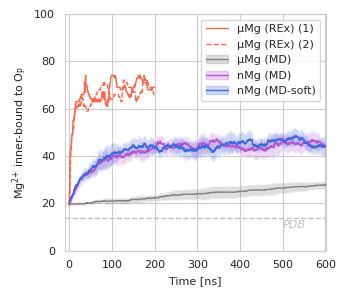

In [11]:
from scipy.ndimage import median_filter, gaussian_filter1d

n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
nrep = 8

fig, ax = plt.subplots(figsize=(3.5, 3))

# Replex
is_bound = []
for replicate in (0, 1):
    d_mg_op_dmx = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

    time = d_mg_op[0, :, 0] / 1000  # ns
    is_bound = d_mg_op[0, :, 2:] < 0.28

    ax.plot(time, median_filter(is_bound.sum(axis=-1), size=99, mode='nearest'), color='tomato', lw=1, label=f'μMg (REx) ({replicate+1})', ls='solid' if replicate == 0 else 'dashed')
    # ax.scatter(time, is_bound.sum(axis=-1), facecolor='tomato', marker='.', s=0.1, alpha=0.2)

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (d_mg_op[:, :, 2:] < 0.28)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='gray', lw=1, label='μMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='gray', alpha=0.25)


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (d_mg_op[:, :, 2:] < 0.28)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='mediumorchid', lw=1, label='nMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumorchid', alpha=0.25)



ff = 'nMg_tip3p_soft'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (d_mg_op[:, :, 2:] < 0.28)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='royalblue', lw=1, label='nMg (MD-soft)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='royalblue', alpha=0.25)


ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(500, n_inner_pdb - 1, 'PDB', style='italic', color='silver', ha='left', va='top')

from matplotlib.patches import Patch
handles, labels = ax.get_legend_handles_labels()
handles[-3:] = [(h, Patch(alpha=0.25, color=h.get_color())) for h in handles[-3:]]

ax.legend(handles, labels, frameon=True, loc='upper right')
ax.set_xlim(-10, 600)
ax.set_ylim(0, 100)
ax.set_xlabel('Time [ns]')
ax.set_ylabel(r'Mg$^{\text{2+}}$ inner-bound to $\mathrm{O_P}$')
#ax.set_title('with PDB ions')

plt.tight_layout()
plt.savefig('figures/inner_mg_op_timeseries.pdf')

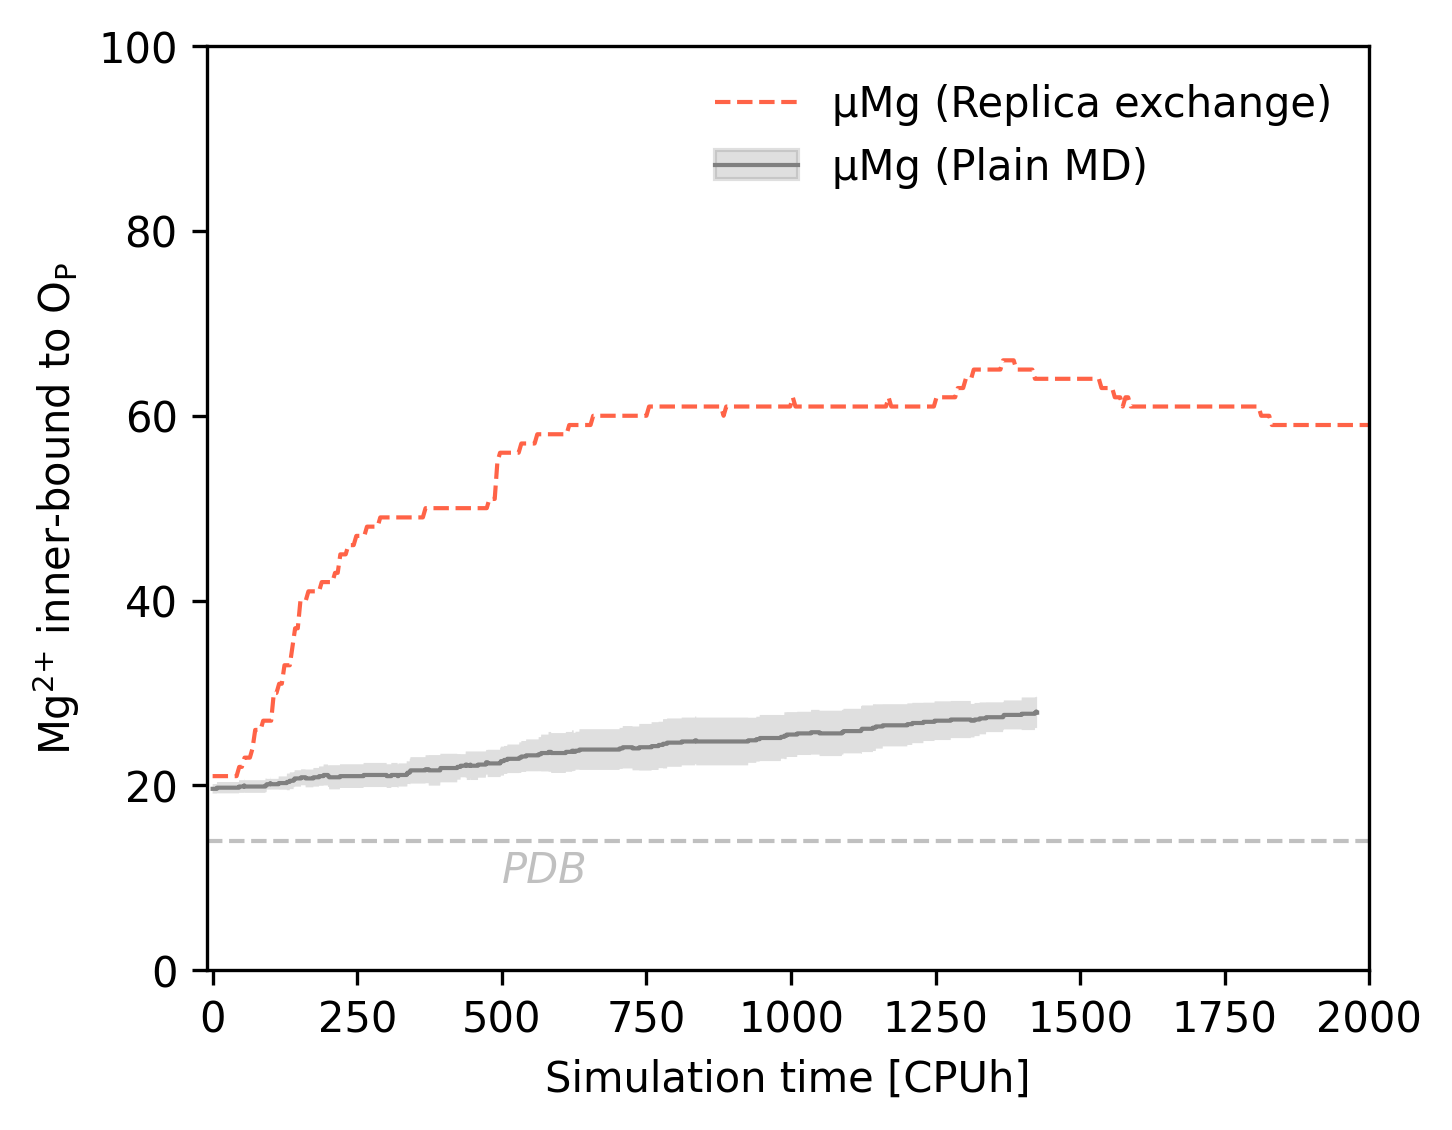

In [ ]:
from scipy.ndimage import median_filter, gaussian_filter1d

n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
nrep = 8
cpu_per_rep = 8

fig, ax = plt.subplots(figsize=(5, 4), dpi=300)

# Replex
is_bound = []

d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

is_bound = d_mg_op[0, :, 2:] < 0.28

ax.plot(cpu_h, median_filter(is_bound.sum(axis=-1), size=99, mode='nearest'), color='tomato', lw=1, label=f'μMg (Replica exchange)', ls='solid' if replicate == 0 else 'dashed')
# ax.scatter(time, is_bound.sum(axis=-1), facecolor='tomato', marker='.', s=0.1, alpha=0.2)

# Plain MD

ff = 'mMg_tip3p'
nrep = 8
cpu_per_rep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * cpu_per_rep
is_bound = (d_mg_op[:, :, 2:] < 0.28)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(cpu_h, n_bound_avg, color='gray', lw=1, label='μMg (Plain MD)')
ax.fill_between(cpu_h, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='gray', alpha=0.25)



ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(500, n_inner_pdb - 1, 'PDB', style='italic', color='silver', ha='left', va='top')

from matplotlib.patches import Patch
handles, labels = ax.get_legend_handles_labels()
handles[-1:] = [(h, Patch(alpha=0.25, color=h.get_color())) for h in handles[-1:]]

ax.legend(handles, labels, frameon=False, loc='upper right')
ax.set_xlim(-10, 2000)
ax.set_ylim(0, 100)
ax.set_xlabel('Simulation time [CPUh]')
ax.set_ylabel(r'Mg$^{\text{2+}}$ inner-bound to $\mathrm{O_P}$')

plt.savefig('figures/inner_mg_op_timeseries_iscra.png')

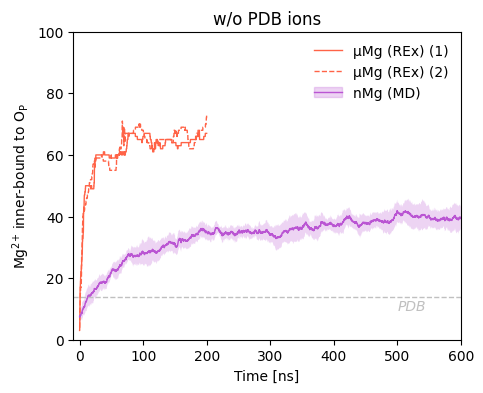

In [30]:
from scipy.ndimage import median_filter, gaussian_filter1d

n_inner_pdb = 14

system = '7ez0_noion'
ff = 'mMg_tip3p'
nrep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
is_bound = []
for replicate in (0, 1):
    d_mg_op_dmx = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

    time = d_mg_op[0, :, 0] / 1000  # ns
    is_bound = d_mg_op[0, :, 2:] < 0.28

    ax.plot(time, median_filter(is_bound.sum(axis=-1), size=99, mode='nearest'), color='tomato', lw=1, label=f'μMg (REx) ({replicate+1})', ls='solid' if replicate == 0 else 'dashed')
    # ax.scatter(time, is_bound.sum(axis=-1), facecolor='tomato', marker='.', s=0.1, alpha=0.2)

# Plain MD

# ff = 'mMg_tip3p_noion'
# nrep = 8

# d_mg_op = [
#     np.insert(
#         np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
#         1,
#         i,
#         axis=-1,
#     )
#     for i in range(nrep)
# ]
# n_frames = max([len(x) for x in d_mg_op])
# d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

# time = d_mg_op[0, :, 0] / 1000  # ns
# is_bound = (d_mg_op[:, :, 2:] < 0.28)


# n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
# n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
# ax.plot(time, n_bound_avg, color='mediumpurple', lw=1, label='μMg (MD)')
# ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumpurple', alpha=0.25)


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = min(map(len, d_mg_op))
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (d_mg_op[:, :, 2:] < 0.28)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='mediumorchid', lw=1, label='nMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumorchid', alpha=0.25)

ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(500, n_inner_pdb - 1, 'PDB', style='italic', color='silver', ha='left', va='top')

handles, labels = ax.get_legend_handles_labels()
handles[-1:] = [(h, Patch(alpha=0.25, color=h.get_color())) for h in handles[-1:]]

ax.legend(handles, labels, frameon=False)
ax.set_xlim(-10, 600)
ax.set_ylim(0, 100)
ax.set_xlabel('Time [ns]')
ax.set_ylabel(r'Mg$^{\text{2+}}$ inner-bound to $\mathrm{O_P}$')
ax.set_title('w/o PDB ions')

plt.savefig('figures/inner_mg_op_timeseries_noion.pdf')

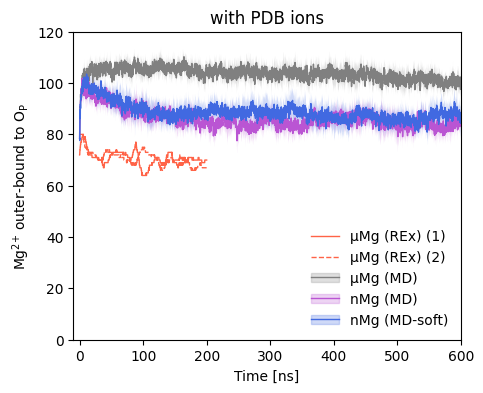

In [26]:
from scipy.ndimage import median_filter, gaussian_filter1d

n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
nrep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
is_bound = []
for replicate in (0, 1):
    d_mg_op_dmx = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

    time = d_mg_op[0, :, 0] / 1000  # ns
    is_bound = (0.28 < d_mg_op[0, :, 2:]) & (d_mg_op[0, :, 2:] < 0.5)

    ax.plot(time, median_filter(is_bound.sum(axis=-1), size=99, mode='nearest'), color='tomato', lw=1, label=f'μMg (REx) ({replicate+1})', ls='solid' if replicate == 0 else 'dashed')
    # ax.scatter(time, is_bound.sum(axis=-1), facecolor='tomato', marker='.', s=0.1, alpha=0.2)

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (0.28 < d_mg_op[:, :, 2:]) & (d_mg_op[:, :, 2:] < 0.5)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='gray', lw=1, label='μMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='gray', alpha=0.25)


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (0.28 < d_mg_op[:, :, 2:]) & (d_mg_op[:, :, 2:] < 0.5)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='mediumorchid', lw=1, label='nMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumorchid', alpha=0.25)



ff = 'nMg_tip3p_soft'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (0.28 < d_mg_op[:, :, 2:]) & (d_mg_op[:, :, 2:] < 0.5)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='royalblue', lw=1, label='nMg (MD-soft)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='royalblue', alpha=0.25)


from matplotlib.patches import Patch
handles, labels = ax.get_legend_handles_labels()
handles[-3:] = [(h, Patch(alpha=0.25, color=h.get_color())) for h in handles[-3:]]

ax.legend(handles, labels, frameon=False, loc='lower right')
ax.set_xlim(-10, 600)
ax.set_ylim(0, 120)
ax.set_xlabel('Time [ns]')
ax.set_ylabel(r'Mg$^{\text{2+}}$ outer-bound to $\mathrm{O_P}$')
ax.set_title('with PDB ions')

plt.savefig('figures/outer_mg_op_timeseries.pdf')

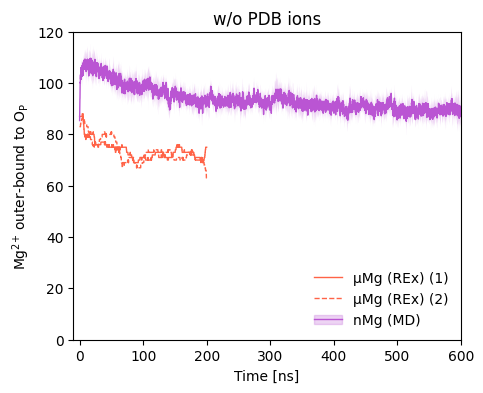

In [29]:
from scipy.ndimage import median_filter, gaussian_filter1d

n_inner_pdb = 14

system = '7ez0_noion'
ff = 'mMg_tip3p'
nrep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
is_bound = []
for replicate in (0, 1):
    d_mg_op_dmx = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

    time = d_mg_op[0, :, 0] / 1000  # ns
    is_bound = (0.28 < d_mg_op[0, :, 2:]) & (d_mg_op[0, :, 2:] < 0.5)

    ax.plot(time, median_filter(is_bound.sum(axis=-1), size=99, mode='nearest'), color='tomato', lw=1, label=f'μMg (REx) ({replicate+1})', ls='solid' if replicate == 0 else 'dashed')
    # ax.scatter(time, is_bound.sum(axis=-1), facecolor='tomato', marker='.', s=0.1, alpha=0.2)

# Plain MD

# ff = 'mMg_tip3p_noion'
# nrep = 8

# d_mg_op = [
#     np.insert(
#         np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
#         1,
#         i,
#         axis=-1,
#     )
#     for i in range(nrep)
# ]
# n_frames = max([len(x) for x in d_mg_op])
# d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

# time = d_mg_op[0, :, 0] / 1000  # ns
# is_bound = (d_mg_op[:, :, 2:] < 0.28)


# n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
# n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
# ax.plot(time, n_bound_avg, color='mediumpurple', lw=1, label='μMg (MD)')
# ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumpurple', alpha=0.25)


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/replicate0/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = min(map(len, d_mg_op))
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

time = d_mg_op[0, :, 0] / 1000  # ns
is_bound = (0.28 < d_mg_op[:, :, 2:]) & (d_mg_op[:, :, 2:] < 0.5)


n_bound_avg = is_bound.sum(axis=-1).mean(axis=0)
n_bound_err = 1.96 * is_bound.sum(axis=-1).std(axis=0) / np.sqrt(nrep - 1)
ax.plot(time, n_bound_avg, color='mediumorchid', lw=1, label='nMg (MD)')
ax.fill_between(time, n_bound_avg - n_bound_err, n_bound_avg + n_bound_err, fc='mediumorchid', alpha=0.25)

handles, labels = ax.get_legend_handles_labels()
handles[-1:] = [(h, Patch(alpha=0.25, color=h.get_color())) for h in handles[-1:]]

ax.legend(handles, labels, frameon=False, loc='lower right')
ax.set_xlim(-10, 600)
ax.set_ylim(0, 120)
ax.set_xlabel('Time [ns]')
ax.set_ylabel(r'Mg$^{\text{2+}}$ outer-bound to $\mathrm{O_P}$')
ax.set_title('w/o PDB ions')

plt.savefig('figures/outer_mg_op_timeseries_noion.pdf')

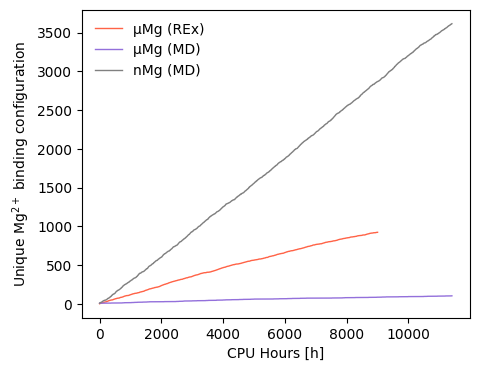

In [5]:
def cumulative_unique(seq):
    """
    Cumulative number of unique elements along sequence.
    """
    out = []
    s = set()
    for x in seq:
        s.add(x)
        out.append(len(s))
    return out

n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
replicate = 0
nrep = 8
cpu_per_rep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep00/bias_index.xvg')

is_bound = (d_mg_op[0, :, 2:] < 0.28)
n_unique = cumulative_unique(map(tuple, is_bound))

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='tomato', lw=1, label='μMg (REx)')

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='mediumpurple', lw=1, label='μMg (MD)')


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='gray', lw=1, label='nMg (MD)')

ax.legend(frameon=False)
ax.set_xlabel('CPU Hours [h]')
ax.set_ylabel(r'Unique Mg$^{2+}$ binding configuration')

plt.savefig('figures/unique_binding_timeseries.pdf')



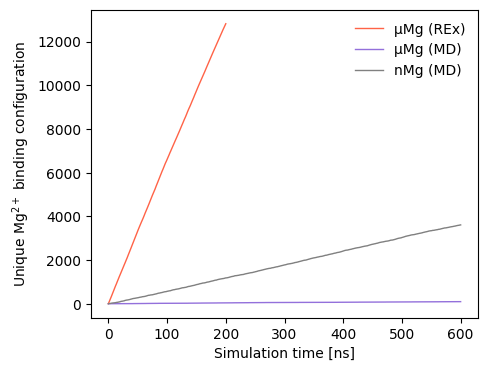

In [9]:
def cumulative_unique(seq):
    """
    Cumulative number of unique elements along sequence.
    """
    out = []
    s = set()
    for x in seq:
        s.add(x)
        out.append(len(s))
    return out

n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
replicate = 0
nrep = 8
cpu_per_rep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep00/bias_index.xvg')

is_bound = (d_mg_op[:, :, 2:] < 0.28)
# n_unique = cumulative_unique(map(tuple, is_bound))
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns

ax.plot(time, n_unique, color='tomato', lw=1, label='μMg (REx)')

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns

ax.plot(time, n_unique, color='mediumpurple', lw=1, label='μMg (MD)')


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns

ax.plot(time, n_unique, color='gray', lw=1, label='nMg (MD)')

ax.legend(frameon=False)
ax.set_xlabel('Simulation time [ns]')
ax.set_ylabel(r'Unique Mg$^{2+}$ binding configuration')

plt.savefig('figures/unique_binding_timeseries.pdf')

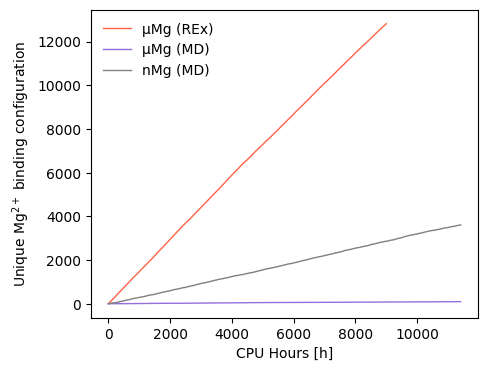

In [11]:
n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
replicate = 0
nrep = 8
cpu_per_rep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep00/bias_index.xvg')

is_bound = (d_mg_op[:, :, 2:] < 0.28)
# n_unique = cumulative_unique(map(tuple, is_bound))
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='tomato', lw=1, label='μMg (REx)')

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='mediumpurple', lw=1, label='μMg (MD)')


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = np.sum([cumulative_unique(map(tuple, is_bound[i])) for i in range(nrep)], axis=0)

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h, n_unique, color='gray', lw=1, label='nMg (MD)')

ax.legend(frameon=False)
ax.set_xlabel('CPU Hours [h]')
ax.set_ylabel(r'Unique Mg$^{2+}$ binding configuration')

plt.savefig('figures/unique_binding_timeseries.pdf')



Total entropy of the average binding vector.

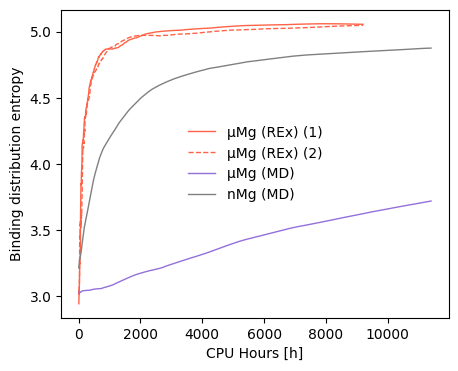

In [44]:
from scipy.stats import entropy

def cumulative_entropy(x):
    return [entropy(x[:i].mean(axis=0)) for i in range(1, len(x))]


n_inner_pdb = 14

system = '7ez0'
ff = 'mMg_tip3p'
nrep = 8
cpu_per_rep = 8

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
for replicate in (0, 1):
    d_mg_op_dmx = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')

    is_bound = (d_mg_op[0, :, 2:] < 0.28)
    # n_unique = cumulative_unique(map(tuple, is_bound))
    n_unique = cumulative_entropy(is_bound)

    time = d_mg_op[0, :, 0] / 1000  # ns
    perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
    cpu_h = time * perf * nrep * cpu_per_rep
    ax.plot(cpu_h[1:], n_unique, color='tomato', lw=1, label=f'μMg (REx) ({replicate+1})', ls='solid' if replicate == 0 else 'dashed')

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = cumulative_entropy(is_bound.mean(axis=0))

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h[1:], n_unique, color='mediumpurple', lw=1, label='μMg (MD)')


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
n_unique = cumulative_entropy(is_bound.mean(axis=0))

time = d_mg_op[0, :, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.plot(cpu_h[1:], n_unique, color='gray', lw=1, label='nMg (MD)')

ax.legend(frameon=False)
ax.set_xlabel('CPU Hours [h]')
ax.set_ylabel(r'Binding distribution entropy')

plt.savefig('figures/bound_distribution_entropy_cpuh.pdf')

Vendi score.

This is sensitive to number of samples so we need to compare at fixed sample count…
-> sample with replacement 

In [15]:
from vendi_score import vendi
from scipy.spatial.distance import pdist, squareform

def vendi_score(x, metric='hamming', n_samples=200, n_bootstrap=5):
    res = []
    for _ in range(n_bootstrap):
        inds = np.random.choice(len(x), size=n_samples)
        _x = x[inds]
        res.append(vendi.score_K(1 - squareform(pdist(_x, metric=metric))))
    avg = np.mean(res)
    stderr = np.std(res)
    return avg, stderr

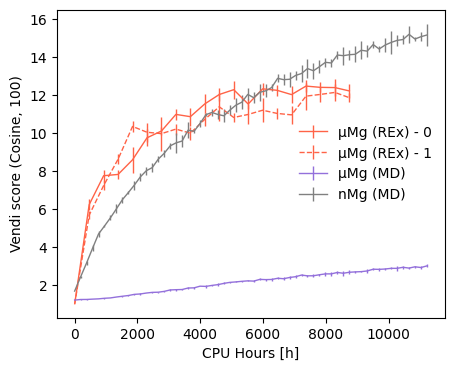

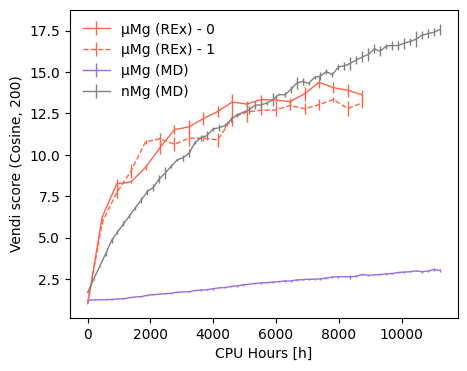

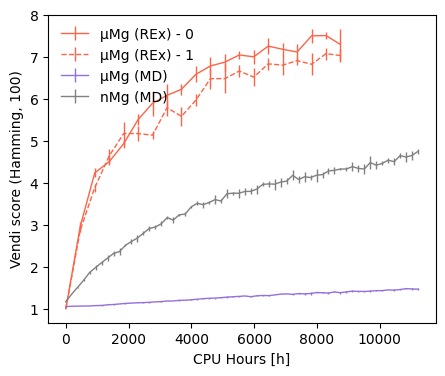

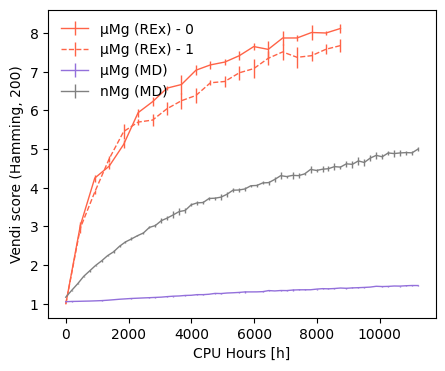

In [21]:
system = '7ez0'
nrep = 8
cpu_per_rep = 8

stride = 100

metrics = ['cosine', 'hamming']
num_samples = [100, 200]

for (metric, n_samples) in itertools.product(metrics, num_samples):
    fig, ax = plt.subplots(figsize=(5, 4))

    # Replex
    ff = 'mMg_tip3p'

    for replicate in (0, 1):

        d_mg_op_dmx = np.stack([
            np.insert(
                np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i+nrep*replicate:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
                1,
                i,
                axis=-1,
            )
            for i in range(nrep)
        ])

        d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{nrep*replicate:02d}/bias_index.xvg')
        is_bound = (d_mg_op[:, :, 2:] < 0.28)

        y, yerr = np.array([vendi_score(is_bound[0, 0:t, :],
                                        metric=metric,
                                        n_samples=n_samples,
                                        ) for t in range(1, is_bound.shape[1], stride)]).T

        time = d_mg_op[0, 1::stride, 0] / 1000  # ns
        perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
        cpu_h = time * perf * nrep * cpu_per_rep

        linestyle = 'solid' if replicate == 0 else 'dashed'
        ax.errorbar(cpu_h, y, yerr=yerr, color='tomato', lw=1, label=f'μMg (REx) - {replicate}', ls=linestyle)


    # Plain MD

    ff = 'mMg_tip3p'
    nrep = 8

    d_mg_op = [
        np.insert(
            np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ]
    n_frames = max([len(x) for x in d_mg_op])
    d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])
    is_bound = (d_mg_op[:, :, 2:] < 0.28)

    y, yerr = np.array([vendi_score(is_bound[:, 0:t, :].reshape(-1, is_bound.shape[-1]),
                                    metric=metric,
                                    n_samples=n_samples,
                                    ) for t in range(1, is_bound.shape[1], stride)]).T

    time = d_mg_op[0, 1::stride, 0] / 1000  # ns
    perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
    cpu_h = time * perf * nrep * cpu_per_rep

    ax.errorbar(cpu_h, y, yerr=yerr, color='mediumpurple', lw=1, label='μMg (MD)')


    ff = 'nMg_tip3p'
    nrep = 8

    d_mg_op = np.stack([
        np.insert(
            np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
            1,
            i,
            axis=-1,
        )
        for i in range(nrep)
    ])

    n_frames = max([len(x) for x in d_mg_op])
    d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

    is_bound = (d_mg_op[:, :, 2:] < 0.28)
    y, yerr = np.array([vendi_score(is_bound[:, 0:t, :].reshape(-1, is_bound.shape[-1]),
                                    metric=metric,
                                    n_samples=n_samples,
                                    ) for t in range(1, is_bound.shape[1], stride)]).T

    time = d_mg_op[0, 1::stride, 0] / 1000  # ns
    perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
    cpu_h = time * perf * nrep * cpu_per_rep

    ax.errorbar(cpu_h, y, yerr=yerr, color='gray', lw=1, label='nMg (MD)')

    ax.legend(frameon=False)
    ax.set_xlabel('CPU Hours [h]')
    ax.set_ylabel(f'Vendi score ({metric.capitalize()}, {n_samples})')

    plt.savefig(f'figures/vendi_{metric}_{n_samples}_cpuh.pdf')

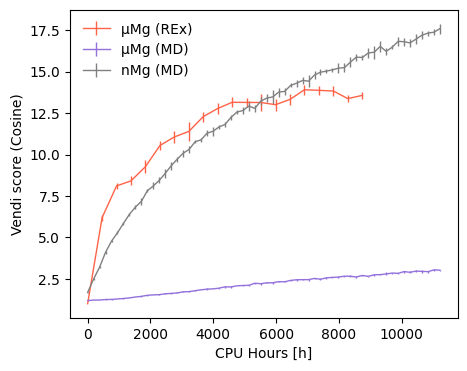

In [ ]:
from vendi_score import vendi
from scipy.spatial.distance import cosine, hamming, pdist, squareform

def vendi_score(x, metric='cosine', n_samples=200, n_bootstrap=5):
    res = []
    for _ in range(n_bootstrap):
        inds = np.random.choice(len(x), size=n_samples)
        _x = x[inds]
        res.append(vendi.score_K(1 - squareform(pdist(_x, metric=metric))))
    avg = np.mean(res)
    stderr = np.std(res)
    return avg, stderr


system = '7ez0'
ff = 'mMg_tip3p'
replicate = 0
nrep = 8
cpu_per_rep = 8

stride = 100

fig, ax = plt.subplots(figsize=(5, 4))

# Replex
d_mg_op_dmx = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

d_mg_op = demux(d_mg_op_dmx, repindex_file=PROJECT_DIR / f'replex/{system}/{ff}/replicate{replicate}/rep00/bias_index.xvg')

is_bound = (d_mg_op[:, :, 2:] < 0.28)

y, yerr = np.array([vendi_score(is_bound[0, 0:t, :]) for t in range(1, is_bound.shape[1], stride)]).T

time = d_mg_op[0, ::stride, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single_bias/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.errorbar(cpu_h[:len(y)], y, yerr=yerr, color='tomato', lw=1, label='μMg (REx)')

# Plain MD

ff = 'mMg_tip3p'
nrep = 8

d_mg_op = [
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
]
n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
y, yerr = np.array([vendi_score(is_bound[:, 0:t, :].reshape(-1, is_bound.shape[-1])) for t in range(1, is_bound.shape[1], stride)]).T

time = d_mg_op[0, ::stride, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.errorbar(cpu_h[:len(y)], y, yerr=yerr, color='mediumpurple', lw=1, label='μMg (MD)')


ff = 'nMg_tip3p'
nrep = 8

d_mg_op = np.stack([
    np.insert(
        np.loadtxt(PROJECT_DIR / f'plain_md/{system}/{ff}/rep{i:02d}/dist_MG_O_Phosphate.xvg', comments=['@', '#']),
        1,
        i,
        axis=-1,
    )
    for i in range(nrep)
])

n_frames = max([len(x) for x in d_mg_op])
d_mg_op = np.stack([x[:n_frames] for x in d_mg_op])

is_bound = (d_mg_op[:, :, 2:] < 0.28)
y, yerr = np.array([vendi_score(is_bound[:, 0:t, :].reshape(-1, is_bound.shape[-1])) for t in range(1, is_bound.shape[1], stride)]).T

time = d_mg_op[0, ::stride, 0] / 1000  # ns
perf = read_performance(PROJECT_DIR / f'benchmark/single/n1.log')  # hour/ns
cpu_h = time * perf * nrep * cpu_per_rep

ax.errorbar(cpu_h[:len(y)], y, yerr=yerr, color='gray', lw=1, label='nMg (MD)')

ax.legend(frameon=False)
ax.set_xlabel('CPU Hours [h]')
ax.set_ylabel(r'Vendi score (Cosine, 200 samples)')

plt.savefig('figures/vendi_cosine_cpuh.pdf')